# Tropical cyclones near the site: CMIP6-HighResMIP

How the number of tropical cyclones (TCs) passing close to the site may change by mid-century, counted directly in the TC tracks of the **CMIP6-HighResMIP high-resolution atmosphere-only models** rather than by shifting the historical tracks (as in [Tropical cyclones](a_tropical_cyclones.ipynb)). Same models, trackers, periods and constrained detection as the [regional TC projections](../../Regional/tropical_cyclones/tc_highresmip.ipynb) and [Li & Zhou (2024)](https://doi.org/10.1038/s41612-024-00704-3):

* four models (CMCC-CM2-VHR4, CNRM-CM6-1-HR, EC-Earth3P-HR, HadGEM3-GC31-HM; all members) and two trackers (TRACK, TempestExtremes);
* present 1980–2010 (`highresSST-present`) vs future 2020–2050 (`highresSST-future`, SSP5-8.5).

A TC is counted when at least one of its track points at TC strength (10-m wind ≥ 34 kt) lies within `radius` degrees (great-circle distance) of the site, the same circle as the IBTrACS analysis. IBTrACS 1980–2010 with the same rule gives the observed reference. The notebook also tests the poleward translation used in [Tropical cyclones](a_tropical_cyclones.ipynb): moving the tracks 1.13° poleward, how much does the count near the site change, compared with what the models project?

```{glue:figure} site_counts_fig
:scale: 60%
:align: center
```

**Figure. Tropical cyclones per year passing within `radius` degrees of the site**: multi-model mean for 1980–2010 and 2020–2050 (SSP5-8.5) for each tracker, each model as a marker, and the observed 1980–2010 mean (dashed line).

In [1]:
# CIndRA notebook display standard
import matplotlib as mpl

mpl.rcParams.update({
    'font.size': 12,
    'axes.titlesize': 15,
    'axes.labelsize': 14,
    'xtick.labelsize': 12,
    'ytick.labelsize': 12,
    'legend.fontsize': 13,
    'figure.dpi': 100,
    'savefig.dpi': 150,
})

## Setup

Track download, point extraction and site counts come from `functions/tc_projections.py`; site configuration from `functions/site_common.py`.

In [2]:
import warnings
warnings.filterwarnings("ignore")

import sys
from pathlib import Path

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from IPython.display import display
from myst_nb import glue

sys.path.append("../../../../functions")
from site_common import load_site_config, list_available_sites, site_config_filename, build_site_tag, build_site_figures_dir, build_site_tables_dir
from tcs import classify_genesis_region
import projections as prj
import tc_projections as tp

### Define location

Set `site_key` to one of the sites configured with [`../../../historical/National/00_site_setup.ipynb`](../../../historical/National/00_site_setup.ipynb) (see the list printed below). The notebook reads the coordinates and country from `data/sites/<site_key>.json`, exactly as the historical notebooks do.

In [3]:
sites_dir = Path("../../../../data/sites")
available_sites = list_available_sites(sites_dir)
print(f"{len(available_sites)} site(s) already configured in {sites_dir}:")
display(available_sites)

6 site(s) already configured in ../../../../data/sites:


,site_key,site_name,country,ghcn_station_id,ghcn_station_name,vars_interest
0,cook_islands_new_zealand_cwm00091843,cook_islands_new_zealand_CWM00091843,Cook Islands [New Zealand],CWM00091843,RAROTONGA INTL GSN 91843,"[TMIN, TMAX, PRCP]"
1,marshall_islands_rmw00040604,marshall_islands_RMW00040604,Marshall Islands,RMW00040604,MH KWAJALEIN GSN 91366,"[TMIN, TMAX, PRCP]"
2,marshall_islands_rmw00040710,marshall_islands_RMW00040710,Marshall Islands,RMW00040710,MH MAJURO WBAS AP GSN 91376,"[TMIN, TMAX, PRCP]"
3,niue_new_zealand_nem00091824,niue_new_zealand_NEM00091824,Niue [New Zealand],NEM00091824,HANAN AIRPORT GSN 91824,"[TMIN, TMAX, PRCP]"
4,palau,Palau,Palau,None,None,None
5,palau_psw00040309,palau_PSW00040309,Palau,PSW00040309,PW KOROR GSN 91408,"[TMIN, TMAX, PRCP]"


In [4]:
site_key = "palau_psw00040309"  # pick a site_key from the table printed above

site_cfg = load_site_config(sites_dir / site_config_filename(site_key))

site_name = site_cfg.get("site_name", "Site")
site_lon = float(site_cfg["site_lon"])
site_lat = float(site_cfg["site_lat"])
country = site_cfg.get("country", site_name)
site_label = country

site_tag = build_site_tag(site_name, site_lon, site_lat)
fig_dir = build_site_figures_dir(Path("../../../../outputs"), site_name, site_lon, site_lat)
tables_dir = build_site_tables_dir(Path("../../../../outputs"), site_name, site_lon, site_lat)
cache_dir = prj.site_cache_dir(site_tag)
print(f"{country}: lon {site_lon}, lat {site_lat} -> figures in {fig_dir}")

Palau: lon 134.4769, lat 7.3367 -> figures in ../../../../outputs/figures/palau_psw00040309_lat7p337_lon134p477


In [5]:
radius = 5  # degrees (great-circle), as in the IBTrACS analysis
shifts = [0.0, 0.5, 1.13, 1.5]  # poleward translations tested (degrees)
ibtracs_file = Path("../../../../data/tcs/tcs_ALL.nc")  # all-basin IBTrACS cache (historical regional TC notebook)
print(f"{country} lies in the {classify_genesis_region(site_lon, site_lat)} subregion")

Palau lies in the Western North Pacific subregion


## HighResMIP tracks

`tp.load_genesis()` gives the members that pass the archive quality control (see the regional notebook) and `tp.load_points()` the TC-strength track points of every member over the tropical Pacific. The first run downloads the track files (~3 GB, deleted after extraction); afterwards only the small cached point files (`data/projections/regional/tcs_highresmip/*_points.npz`) are read, for any site and radius.

In [6]:
genesis, qc = tp.load_genesis(verbose=False, return_qc=True)
points = tp.load_points(qc)
obs_points = tp.observed_points(xr.load_dataset(ibtracs_file), 1980, 2010)
observed = len(tp.site_passages(obs_points, site_lon, site_lat, radius)) / 31
print(f"Observed (IBTrACS) TCs within {radius}° of {country}, 1980–2010: {observed:.2f} per year")

Observed (IBTrACS) TCs within 5° of Palau, 1980–2010: 2.35 per year


## Number of tropical cyclones near the site

TCs per year passing within `radius` degrees of the site, for every model (mean of its members) and the multi-model mean of each tracker, and the % change from 1980–2010 to 2020–2050.

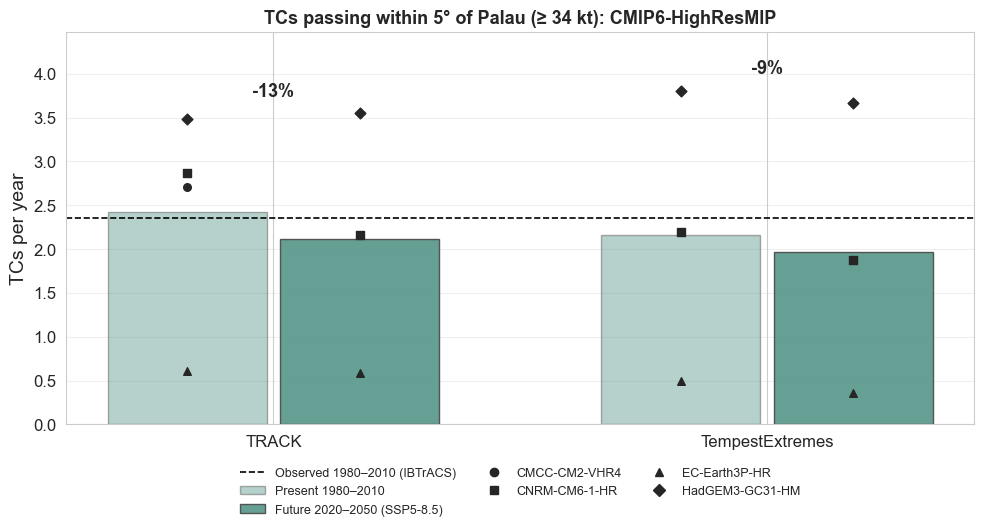

period,Tracker,Model,Future 2020–2050 (TCs/yr),Present 1980–2010 (TCs/yr),Change (%)
0,TRACK,CMCC-CM2-VHR4,2.16,2.71,-20.24
1,TRACK,CNRM-CM6-1-HR,2.16,2.87,-24.72
2,TRACK,EC-Earth3P-HR,0.59,0.61,-4.27
3,TRACK,HadGEM3-GC31-HM,3.55,3.48,1.85
4,TempestExtremes,CNRM-CM6-1-HR,1.87,2.19,-14.71
5,TempestExtremes,EC-Earth3P-HR,0.36,0.49,-26.74
6,TempestExtremes,HadGEM3-GC31-HM,3.67,3.81,-3.67
7,TRACK,Multi-model mean,2.11,2.42,-12.60
8,TempestExtremes,Multi-model mean,1.97,2.16,-9.16


In [7]:
counts = tp.site_counts(points, site_lon, site_lat, radius, shifts)
change = tp.site_change_table(counts)
prj.save_table(change.round(2), tables_dir, "tc_highresmip_site_counts", site_tag)

fig = tp.plot_site_counts(change, observed, site_label=country, radius=radius)
prj.save_figure(fig, fig_dir, "tc_highresmip_site_counts", site_tag)
glue("site_counts_fig", fig, display=False)
plt.show()
change.round(2)

## Tracks near the site

Tracks of the model TCs passing within `radius` degrees of the site, 1980–2010 (left) vs 2020–2050 (right), for one member of each model (`member_index`) so the panels compare equal record lengths. Each track is coloured by the Saffir–Simpson class of the storm's lifetime minimum central pressure (see *Categories* below); dots mark where each storm first reaches TC strength (its genesis). Compare with the historical and shifted IBTrACS tracks of [Tropical cyclones](a_tropical_cyclones.ipynb).

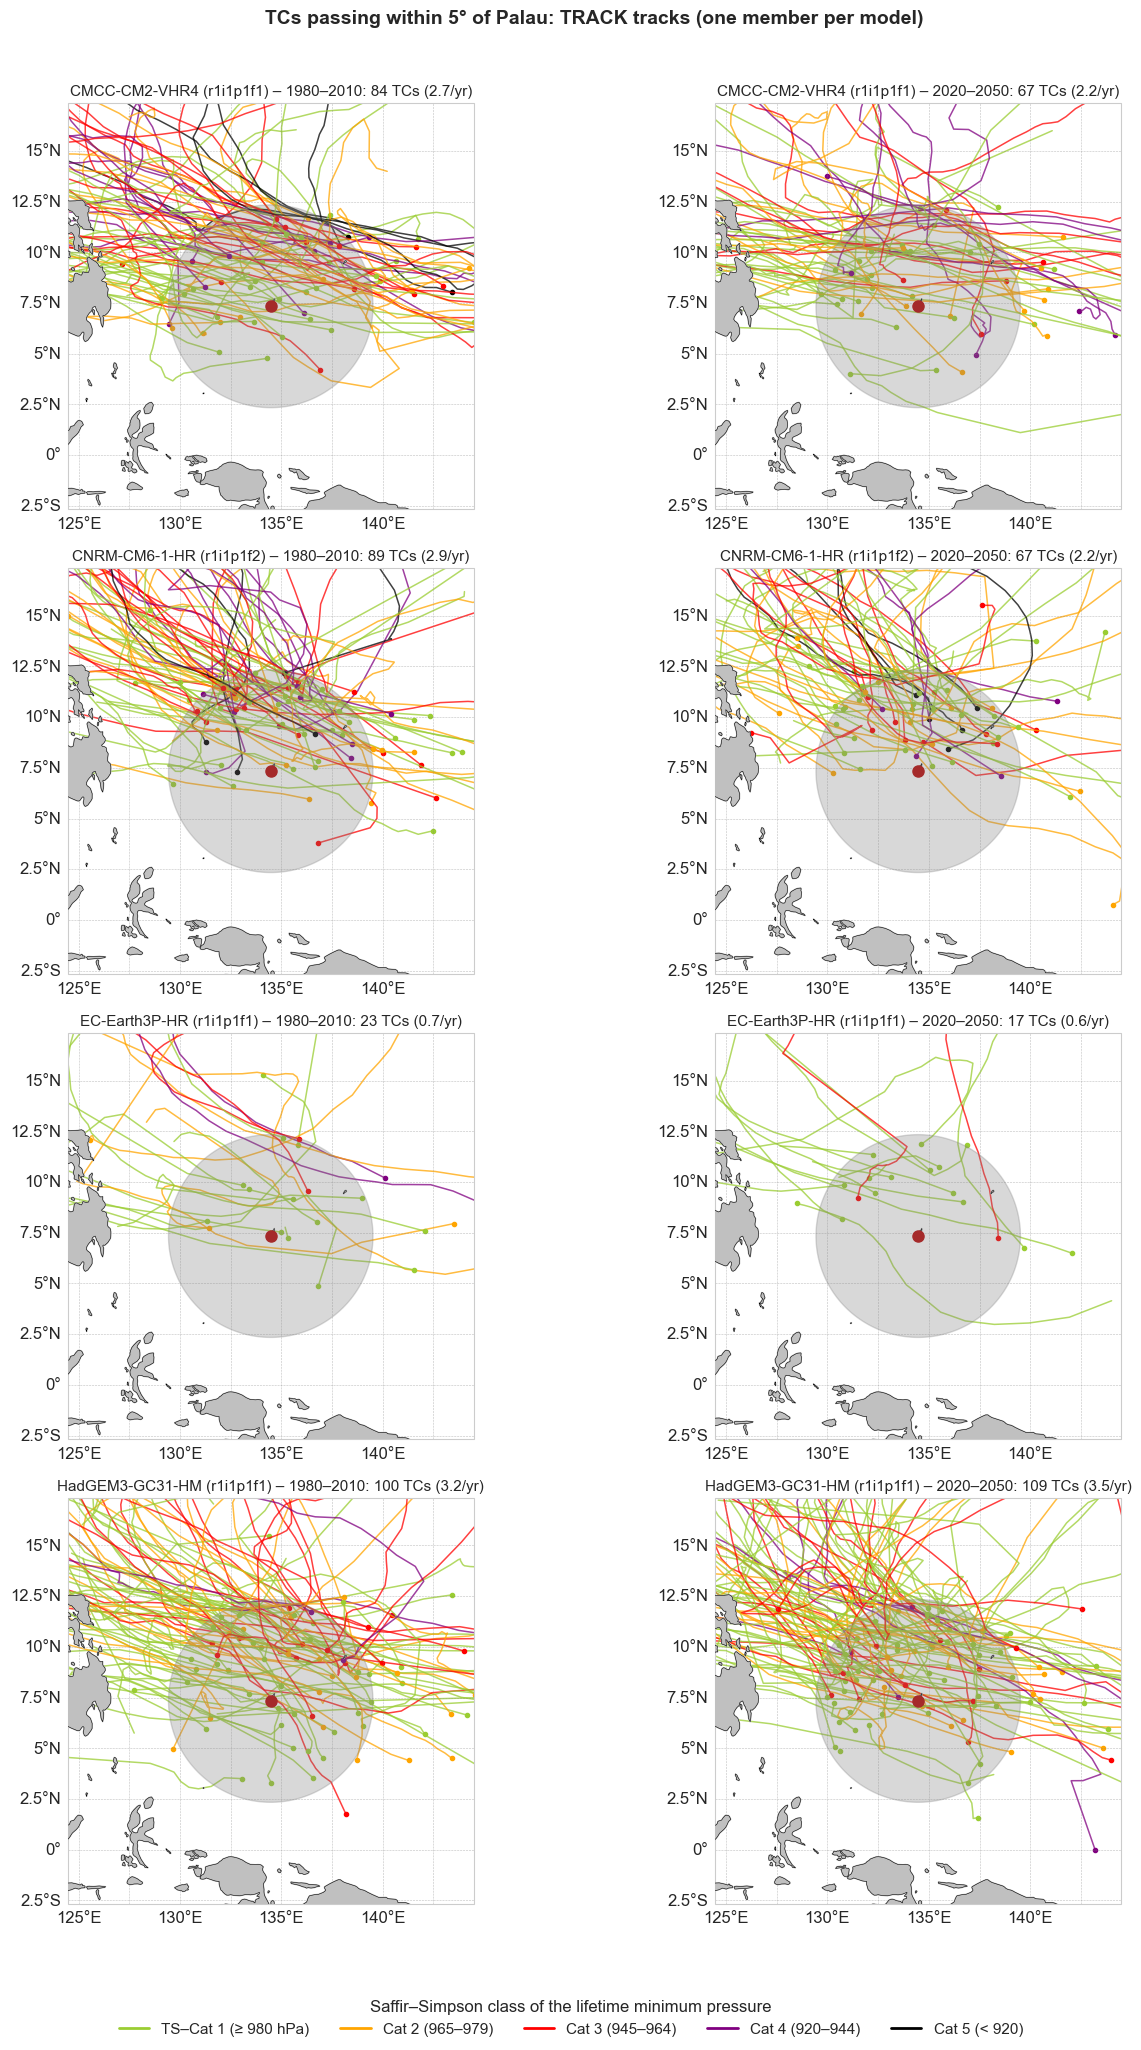

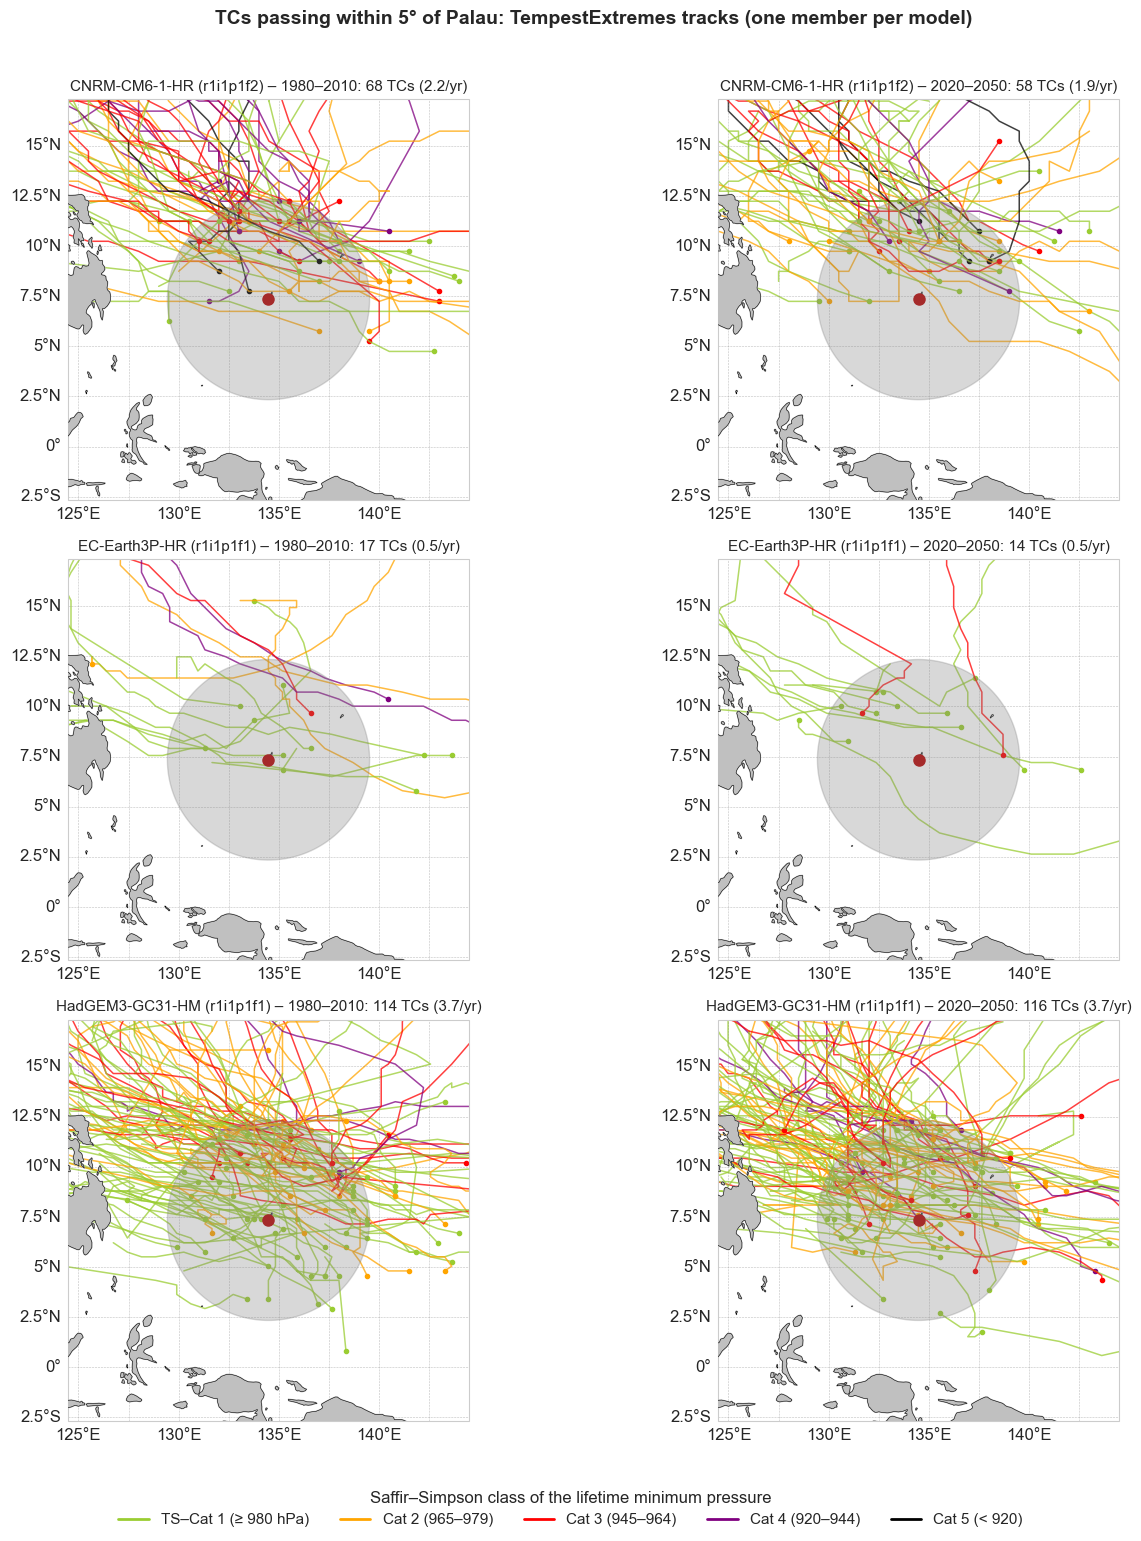

In [8]:
member_index = 0
for tracker in tp.TRACKERS:
    fig = tp.plot_site_tracks(points, site_lon, site_lat, radius, tracker=tracker, member_index=member_index, site_label=country)
    prj.save_figure(fig, fig_dir, f"tc_highresmip_site_tracks_{tracker}", site_tag)
    plt.show()

## Track density

Multi-model mean density of TC track points (TC days per year per 1° cell, smoothed) over the basin: the 1980–2010 density with the 2020–2050 contours (left) and the reverse (right), as the historical-vs-shifted density figure of [Tropical cyclones](a_tropical_cyclones.ipynb). Here the future field comes from the models' own 2020–2050 tracks instead of a translation of the historical ones.

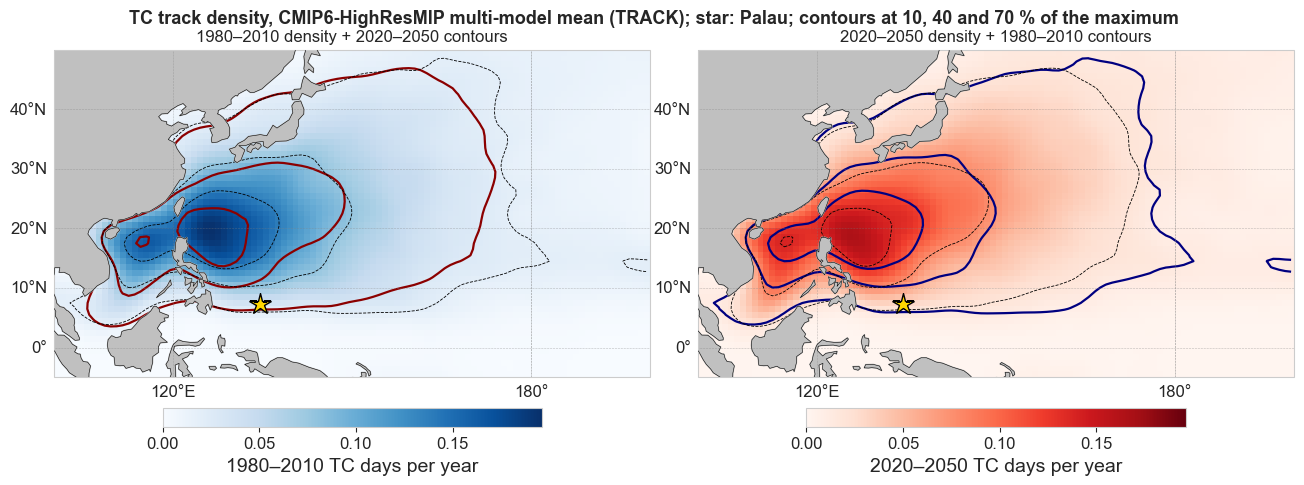

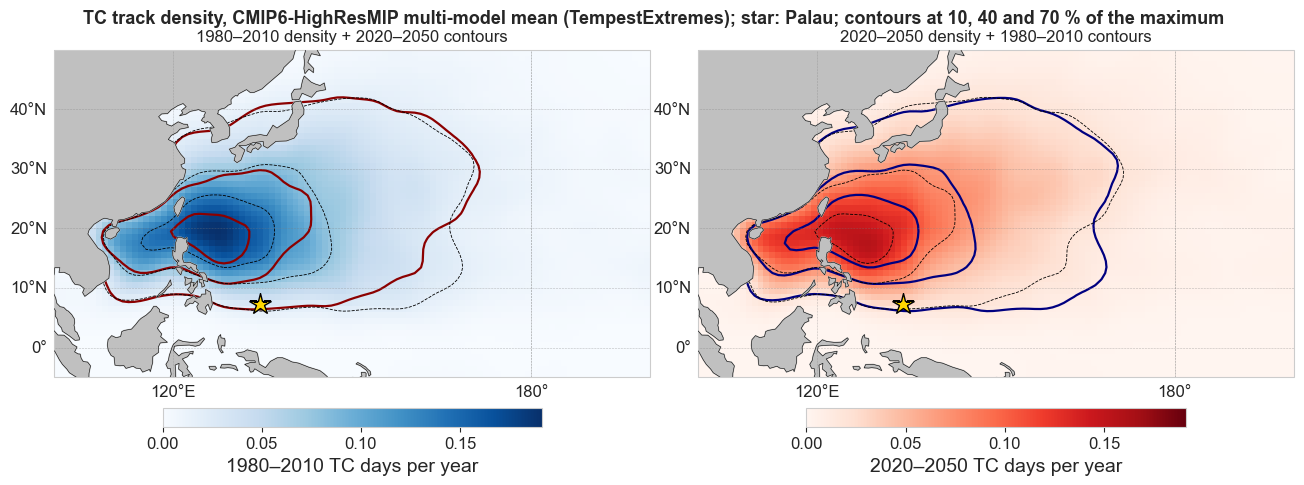

In [9]:
for tracker in tp.TRACKERS:
    fig = tp.plot_site_density(points, site_lon, site_lat, tracker=tracker, site_label=country)
    prj.save_figure(fig, fig_dir, f"tc_highresmip_site_density_{tracker}", site_tag)
    plt.show()

## Categories

The 25–75 km models underestimate the maximum winds of tropical cyclones, so wind-based Saffir–Simpson categories would put almost every model storm in the lowest classes. As in HighResMIP studies (Roberts et al., 2020; Li & Zhou, 2024), storms are classified here by their **minimum central pressure** over their lifetime, with the pressure ranges of the Saffir–Simpson scale: category 2 at 965–979 hPa, 3 at 945–964 hPa, 4 at 920–944 hPa and 5 below 920 hPa. The scale gives no pressure limit between tropical storms and category 1, so both form one class (≥ 980 hPa). The observed IBTrACS storms (WMO pressure) are classified the same way, so model and observed distributions are comparable.

The table and figure give the TCs per year passing within `radius` degrees of the site in each class (multi-model mean of each tracker).

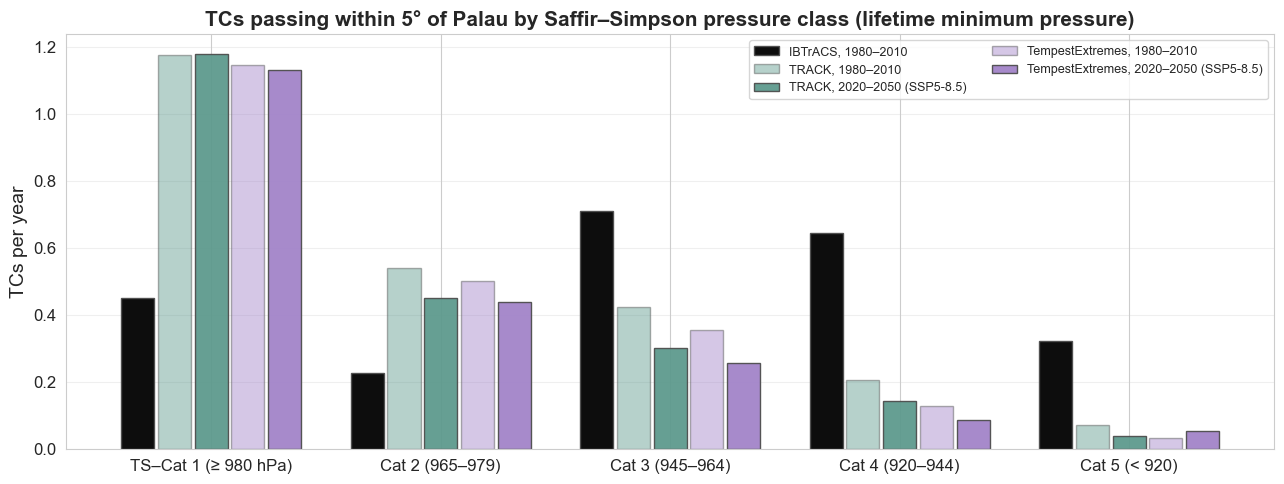

TS–Cat 1 (≥ 980 hPa)  Cat 2 (965–979)  \
Source          Period                                                        
IBTrACS         1980–2010                             0.45             0.23   
TRACK           1980–2010                             1.17             0.54   
                2020–2050 (SSP5-8.5)                  1.18             0.45   
TempestExtremes 1980–2010                             1.15             0.50   
                2020–2050 (SSP5-8.5)                  1.13             0.44   

                                      Cat 3 (945–964)  Cat 4 (920–944)  \
Source          Period                                                   
IBTrACS         1980–2010                        0.71             0.65   
TRACK           1980–2010                        0.42             0.21   
                2020–2050 (SSP5-8.5)             0.30             0.14   
TempestExtremes 1980–2010                        0.35             0.13   
                2020–2050 (SSP5-8.5)             0.26             0.09   

                                      Cat 5 (< 920)  
Source          Period                               
IBTrACS         1980–2010                      0.32  
TRACK           1980–2010                      0.07  
                2020–2050 (SSP5-8.5)           0.04  
TempestExtremes 1980–2010                      0.03  
                2020–2050 (SSP5-8.5)           0.05

In [10]:
obs_points = tp.observed_points(xr.load_dataset(ibtracs_file), 1980, 2010)  # with pressure
categories = tp.site_category_counts(points, site_lon, site_lat, radius, observed=obs_points)
prj.save_table(categories.round(3).reset_index(), tables_dir, "tc_highresmip_site_categories", site_tag)

classes = list(categories.columns)
bars = list(categories.index)
colors = {"IBTrACS": "black", "TRACK": "#5E9A8D", "TempestExtremes": "#A284C9"}
width = 0.8 / len(bars)
fig, ax = plt.subplots(figsize=(13, 5))
for k, (source, period) in enumerate(bars):
    x = np.arange(len(classes)) + (k - (len(bars) - 1) / 2) * width
    ax.bar(x, categories.loc[(source, period)].values, width=width * 0.9, color=colors[source],
           alpha=0.45 if period == "1980–2010" and source != "IBTrACS" else 0.95, edgecolor="0.3", label=f"{source}, {period}")
ax.set_xticks(np.arange(len(classes)))
ax.set_xticklabels(classes)
ax.set_ylabel("TCs per year")
ax.set_title(f"TCs passing within {radius}° of {country} by Saffir–Simpson pressure class (lifetime minimum pressure)",
             fontweight="bold")
ax.legend(fontsize=9, ncol=2)
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
prj.save_figure(fig, fig_dir, "tc_highresmip_site_categories", site_tag)
plt.show()
categories.round(2)

## Projected change vs a poleward translation

The approach of [Tropical cyclones](a_tropical_cyclones.ipynb) moves every track 1.13° poleward and counts the storms that still pass near the site. Here the same translation (and 0.5° and 1.5°) is applied to each model's **present** tracks and compared with the change that model actually projects for 2020–2050; the last row applies it to the observed IBTrACS tracks, as the other notebook does. If the translation is a good proxy, the projected and translated changes should be similar.

In [11]:
obs_by_shift = pd.Series({s: len(tp.site_passages(obs_points, site_lon, site_lat, radius, s)) / 31 for s in shifts})
translation = tp.translation_vs_projection(counts, obs_by_shift)
prj.save_table(translation.round(1), tables_dir, "tc_highresmip_site_translation", site_tag)
translation.round(1)

,Tracker,Model,Projected (models),Translation 0.5°,Translation 1.13°,Translation 1.5°
0,TRACK,CMCC-CM2-VHR4,-20.2,-7.1,-16.7,-26.2
1,TRACK,CNRM-CM6-1-HR,-24.7,-12.4,-34.8,-49.4
2,TRACK,EC-Earth3P-HR,-4.3,-15.8,-29.8,-36.8
3,TRACK,HadGEM3-GC31-HM,1.9,-15.1,-26.9,-31.8
4,TempestExtremes,CNRM-CM6-1-HR,-14.7,-11.8,-33.8,-51.5
5,TempestExtremes,EC-Earth3P-HR,-26.7,-15.2,-21.7,-32.6
6,TempestExtremes,HadGEM3-GC31-HM,-3.7,-14.1,-26.8,-32.2
7,TRACK,Multi-model mean,-11.8,-12.6,-27.0,-36.1
8,TempestExtremes,Multi-model mean,-15.0,-13.7,-27.5,-38.8
9,IBTrACS,Observed 1980–2010,NaN,-12.3,-30.1,-42.5


## Seasonal cycle and intensity

Multi-model mean TCs per year passing near the site, by month of genesis and by maximum 10-m wind inside the circle. The 25–75 km models underestimate the strongest winds, so the wind classes compare present and future within the models and are not equivalent to the Saffir–Simpson categories of IBTrACS.

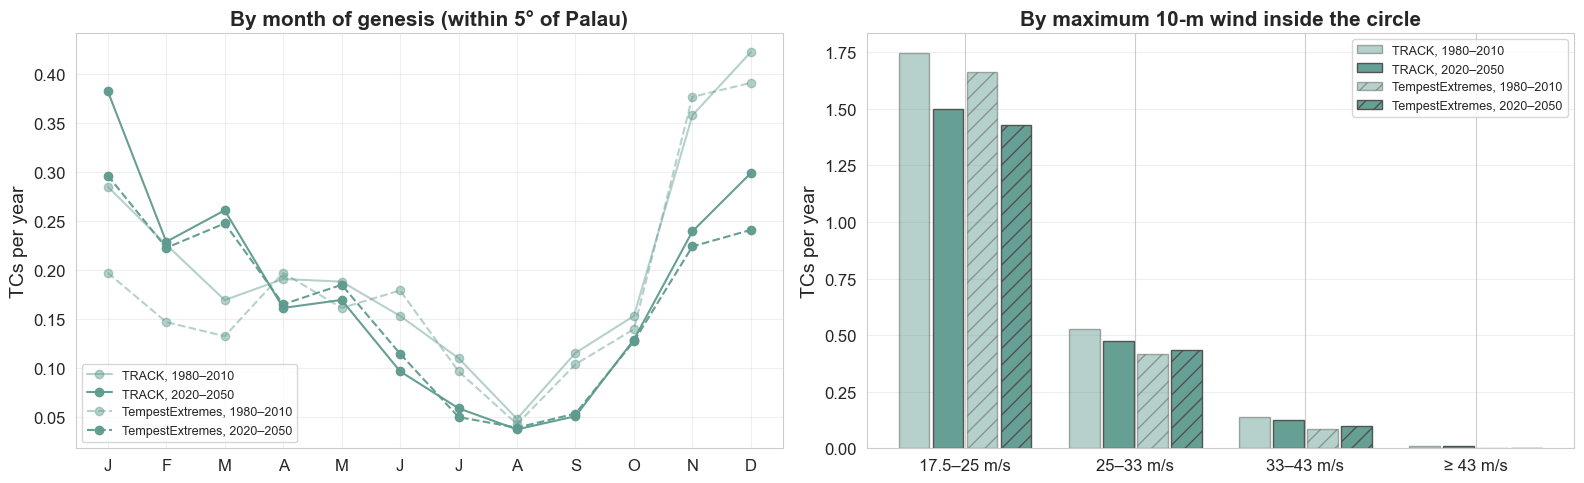

17.5–25 m/s  25–33 m/s  33–43 m/s  ≥ 43 m/s
tracker period                                              
TRACK   future          1.50       0.47       0.12      0.01
        present         1.75       0.53       0.14      0.01
TempExt future          1.43       0.44       0.10      0.00
        present         1.66       0.42       0.09      0.00

In [12]:
monthly = tp.site_monthly(points, site_lon, site_lat, radius)
intensity = tp.site_intensity(points, site_lon, site_lat, radius)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
months = np.arange(1, 13)
for k, tracker in enumerate(tp.TRACKERS):
    for period, alpha in (("present", 0.45), ("future", 0.95)):
        axes[0].plot(months, monthly.loc[(tracker, period)].values, marker="o", linestyle="-" if k == 0 else "--",
                     color="#5E9A8D", alpha=alpha, label=f"{tp.TRACKER_LABEL[tracker]}, {'1980–2010' if period == 'present' else '2020–2050'}")
axes[0].set_xticks(months)
axes[0].set_xticklabels(["J", "F", "M", "A", "M", "J", "J", "A", "S", "O", "N", "D"])
axes[0].set_ylabel("TCs per year")
axes[0].set_title(f"By month of genesis (within {radius}° of {country})", fontweight="bold")
axes[0].legend(fontsize=9)
axes[0].grid(alpha=0.3)

classes = list(intensity.columns)
width = 0.2
for k, tracker in enumerate(tp.TRACKERS):
    for j, period in enumerate(("present", "future")):
        x = np.arange(len(classes)) + (2 * k + j - 1.5) * width
        axes[1].bar(x, intensity.loc[(tracker, period)].values, width=width * 0.9, color="#5E9A8D",
                    alpha=0.45 if period == "present" else 0.95, hatch=None if k == 0 else "//", edgecolor="0.3",
                    label=f"{tp.TRACKER_LABEL[tracker]}, {'1980–2010' if period == 'present' else '2020–2050'}")
axes[1].set_xticks(np.arange(len(classes)))
axes[1].set_xticklabels(classes)
axes[1].set_ylabel("TCs per year")
axes[1].set_title(f"By maximum 10-m wind inside the circle", fontweight="bold")
axes[1].legend(fontsize=9)
axes[1].grid(axis="y", alpha=0.3)
fig.tight_layout()
prj.save_figure(fig, fig_dir, "tc_highresmip_site_season_intensity", site_tag)
plt.show()

prj.save_table(monthly.round(3).reset_index(), tables_dir, "tc_highresmip_site_monthly", site_tag)
prj.save_table(intensity.round(3).reset_index(), tables_dir, "tc_highresmip_site_intensity", site_tag)
intensity.round(2)

## Interpretation and reproducibility notes

Values quoted here are those of the run documented in this notebook, for Palau (Koror) and a 5° radius.

- **Fewer TCs near Palau.** The models project about −9 % (TempestExtremes) to −13 % (TRACK) fewer TCs passing within 5° in 2020–2050 than in 1980–2010 (change of the multi-model means). Individual models range from about −27 % to +2 %, so the sign is consistent in most but not all models.
- **The 1.13° translation overstates the decrease.** Moving each model's own present tracks 1.13° poleward reduces the count by about −27 %, two to three times the change the same models project; applied to IBTrACS, as in [Tropical cyclones](a_tropical_cyclones.ipynb), it gives −30 %. A translation of about 0.5° reproduces the projected change (−12 to −14 %). This agrees with the regional analysis: the tracks of the western North Pacific move less than the genesis point, and part of the change is a loss of activity rather than a displacement.
- **Model bias.** Present-day counts range from about 0.5 (EC-Earth3P-HR) to 3.8 (HadGEM3-GC31-HM) TCs per year against 2.35 observed; the % change is more robust than the absolute number.
- **Categories.** Classified by lifetime minimum pressure, the weaker storms (≥ 965 hPa: tropical storm to category 2) change little, while the decrease near Palau comes mainly from categories 3–4 (about −25 to −35 % in the multi-model means). The models produce far fewer intense storms than observed: about 0.4–0.7 TCs per year of category 3 or stronger against 1.7 in IBTrACS, so the absolute numbers by category are not reliable, only the relative change within the models.
- **Winds.** Most model TCs near Palau stay below 33 m/s; the models underestimate the strongest winds, which is why categories are based on pressure.
- **Tracks and density.** The track maps and the basin density show the same picture as the counts: the main TC corridor of the western North Pacific stays in place, while activity weakens on its equatorward edge, where Palau lies, rather than the whole corridor moving north.
- **Scenario and horizon.** SSP5-8.5, 2020–2050 only (the HighResMIP atmosphere-only future runs); 31 years and a few members per model, so internal variability is a large part of the model-to-model spread.
- **Counting rule.** A TC counts when one of its 6-hourly points at ≥ 34 kt lies within the circle; [Tropical cyclones](a_tropical_cyclones.ipynb) counts every IBTrACS storm crossing the circle, including weaker stages, so its totals are larger.

**References:** Li & Zhou (2024), *npj Clim. Atmos. Sci.* 7, 161, [doi:10.1038/s41612-024-00704-3](https://doi.org/10.1038/s41612-024-00704-3); Roberts et al. (2020), *J. Climate* 33, 2557–2583; Roberts (2019), CMIP6 HighResMIP tropical storm tracks, CEDA (CC BY 4.0); Knapp et al. (2010), IBTrACS, *BAMS* 91, 363–376.
